# Balanced arXiv IMSTE experiments

This notebook uses a reproducible subset of the full prepared vector cache so configuration experiments finish quickly. The default is 32,000 unique papers, sampled evenly across the eight domains (4,000 per domain). The requested number per class is capped by the smallest available class. Balanced selection never duplicates papers; change `TARGET_PER_CLASS` or `SAMPLE_MODE` to control the experiment subset. For a 640,000-row random confirmation run, set `SAMPLE_MODE = "random"` and `TARGET_PER_CLASS = 80_000`; for quick balanced runs, keep the default 4,000 per domain.

UMAP is fitted only as a comparison reference. **No IMSTE run uses UMAP coordinates or UMAP initialization.** IMSTE variants start independently from PCA, spectral, or random coordinates, then test multilevel refinement, optimizer and repulsion settings, and local-neighbor graph alternatives. The notebook reports neighborhood fidelity, domain purity, relative local radius, and runtime. Subset and model settings are included in cache identities.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import time
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks" / "src"))
from arxiv_dataset import load_arxiv_dataset
from arxiv_imste import select_arxiv_experiment_subset

DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
CACHE_DIR = DATA_DIR / "cache"
EXPERIMENT_CACHE_DIR = CACHE_DIR / "balanced_experiments"
EXPERIMENT_CACHE_DIR.mkdir(parents=True, exist_ok=True)
papers, X_full, data_manifest = load_arxiv_dataset(DATA_DIR)

primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")
domain_order = domain.value_counts().index.tolist()
labels_full = pd.Categorical(domain, categories=domain_order)

# Change these controls to run a smaller, reproducible experiment.
SAMPLE_MODE = "balanced"  # "balanced", "random", or "full"
TARGET_PER_CLASS = 4_000
SAMPLE_RANDOM_STATE = int(data_manifest["random_state"])
if SAMPLE_MODE == "balanced":
    counts = np.unique(np.asarray(labels_full), return_counts=True)[1]
    AVAILABLE_PER_CLASS = int(counts.min())
    PER_CLASS = min(TARGET_PER_CLASS, AVAILABLE_PER_CLASS)
    SAMPLE_SIZE = len(counts) * PER_CLASS
    if PER_CLASS < TARGET_PER_CLASS:
        print(f"Balanced sample capped at {PER_CLASS:,} rows per class by the minority class size.")
else:
    SAMPLE_SIZE = TARGET_PER_CLASS * len(np.unique(np.asarray(labels_full)))
X_experiment, labels_experiment, experiment_data_id = select_arxiv_experiment_subset(
    X_full,
    labels_full,
    dataset_id=data_manifest["dataset_id"],
    mode=SAMPLE_MODE,
    sample_size=SAMPLE_SIZE,
    random_state=SAMPLE_RANDOM_STATE,
)
print(f"Source data: {len(X_full):,} papers × {X_full.shape[1]:,} features")
print(f"Experiment subset: {len(X_experiment):,} rows ({SAMPLE_MODE}), ID {experiment_data_id}")
print(pd.Series(np.asarray(labels_experiment)).value_counts().sort_index().to_string())

# Shared geometry settings. Keep these fixed when comparing initializations.
RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
IMSTE_N_MSTS = 5
IMSTE_N_EPOCHS = 100
IMSTE_BATCH_SIZE = 32768
IMSTE_LEARNING_RATE = 0.05
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.05
IMSTE_LOGISTIC_MARGIN = 0.25
IMSTE_LOGISTIC_TEMPERATURE = 0.5
IMSTE_DEVICE = "mps"  # Set to "auto" or "cpu" when MPS is unavailable.
IMSTE_MST_NEIGHBOR_BACKEND = "rinnd"


Source data: 1,200,000 papers × 384 features
Experiment subset: 32,000 rows (balanced), ID c2e0ceee03fc5e6b00b2
biology             4000
computer science    4000
economics           4000
engineering         4000
finance             4000
mathematics         4000
physics             4000
statistics          4000


In [2]:
import umap

umap_settings = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": 4,
    "metric": METRIC,
    "init": "recursive",
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
}
umap_key = hashlib.sha256(
    json.dumps({"data_id": experiment_data_id, **umap_settings}, sort_keys=True).encode()
).hexdigest()[:16]
umap_cache_path = EXPERIMENT_CACHE_DIR / f"umap_{umap_key}.npz"
if umap_cache_path.is_file():
    saved = np.load(umap_cache_path, allow_pickle=False)
    Z_umap = saved["embedding"]
    umap_seconds = float(saved["seconds"])
    print("Loaded cached subset UMAP:", umap_cache_path.name)
else:
    started = time.perf_counter()
    Z_umap = umap.UMAP(verbose=True, **umap_settings).fit_transform(X_experiment)
    umap_seconds = time.perf_counter() - started
    np.savez_compressed(
        umap_cache_path,
        embedding=np.asarray(Z_umap, dtype=np.float32),
        seconds=np.asarray(umap_seconds),
        settings_json=np.asarray(json.dumps(umap_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"Subset UMAP fit: {umap_seconds:.2f}s")


Loaded cached subset UMAP: umap_ab0482a52f52ecba.npz


In [3]:
from imste import IteratedMinimumSpanningTreeEmbedder
from imste.mst.famst import _ann_edges_rinnd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.manifold import SpectralEmbedding

# Independent local-graph spectral initialization (cached by data and settings).
spectral_settings = {"neighbors": N_NEIGHBORS, "affinity": "kth_neighbor_scale_rbf", "random_state": RANDOM_STATE}
spectral_key = hashlib.sha256(
    json.dumps({"data_id": experiment_data_id, **spectral_settings}, sort_keys=True).encode()
).hexdigest()[:16]
spectral_path = EXPERIMENT_CACHE_DIR / f"spectral_init_{spectral_key}.npz"
if spectral_path.is_file():
    Z_spectral = np.load(spectral_path, allow_pickle=False)["embedding"]
    print("Loaded cached spectral initialization:", spectral_path.name)
else:
    edge_map = _ann_edges_rinnd(
        X_experiment, N_NEIGHBORS, RANDOM_STATE, verbose=False
    )
    pairs = np.asarray(list(edge_map), dtype=np.int64)
    distances = np.fromiter(edge_map.values(), dtype=np.float64, count=len(edge_map))
    rows = np.r_[pairs[:, 0], pairs[:, 1]]
    cols = np.r_[pairs[:, 1], pairs[:, 0]]
    distance_graph = coo_matrix(
        (np.r_[distances, distances], (rows, cols)),
        shape=(len(X_experiment), len(X_experiment)),
    ).tocsr()
    local_scale = np.empty(len(X_experiment), dtype=np.float64)
    for node in range(len(X_experiment)):
        incident = distance_graph.data[
            distance_graph.indptr[node] : distance_graph.indptr[node + 1]
        ]
        rank = min(N_NEIGHBORS, len(incident)) - 1
        local_scale[node] = np.partition(incident, rank)[rank]
    affinity = np.exp(
        -(distances**2)
        / np.maximum(local_scale[pairs[:, 0]] * local_scale[pairs[:, 1]], 1e-12)
    )
    weights = np.r_[affinity, affinity]
    neighborhood_graph = coo_matrix(
        (weights, (rows, cols)), shape=(len(X_experiment), len(X_experiment))
    ).tocsr()
    components = connected_components(neighborhood_graph, directed=False, return_labels=False)
    if components != 1:
        raise RuntimeError(f"Spectral initialization graph has {components} components.")
    Z_spectral = SpectralEmbedding(
        n_components=2, affinity="precomputed", eigen_solver="lobpcg", eigen_tol=1e-3,
        random_state=RANDOM_STATE,
    ).fit_transform(neighborhood_graph)
    Z_spectral /= max(float(np.max(np.abs(Z_spectral))), 1e-12)
    np.savez_compressed(
        spectral_path, embedding=np.asarray(Z_spectral, dtype=np.float32),
        settings_json=np.asarray(json.dumps(spectral_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"Spectral initialization fit: {spectral_path.name}")

IMSTE_COMMON_SETTINGS = {
    "n_components": 2,
    "n_msts": IMSTE_N_MSTS,
    "n_epochs": IMSTE_N_EPOCHS,
    "batch_size": IMSTE_BATCH_SIZE,
    "learning_rate": IMSTE_LEARNING_RATE,
    "negative_ratio": IMSTE_NEGATIVE_RATIO,
    "lambda_rep": IMSTE_LAMBDA_REP,
    "random_state": RANDOM_STATE,
    "device": IMSTE_DEVICE,
    "logistic_margin": IMSTE_LOGISTIC_MARGIN,
    "logistic_temperature": IMSTE_LOGISTIC_TEMPERATURE,
    "mst_method": "famst",
    "mst_neighbor_backend": IMSTE_MST_NEIGHBOR_BACKEND,
    "mst_neighbors": N_NEIGHBORS,
    "mst_inter_component_edges": 5,
    "mst_representatives_per_component": 10,
    "mst_max_neighbors": None,
    "include_knn_attraction": False,
    "pca_init": True,
    "pca_init_scaling": "global",
    "multilevel_init": True,
    "multilevel_reduction_ratio": 8,
    "multilevel_base_size": 512,
    "multilevel_epochs": 10,
    "metric": METRIC,
    "verbose": False,
}

def fit_imste_variant(name, overrides=None, init_coordinates=None, init_id=None):
    settings = {**IMSTE_COMMON_SETTINGS, **(overrides or {}), "init_coordinates_id": init_id}
    key = hashlib.sha256(
        json.dumps(
            {"data_id": experiment_data_id, "name": name, "settings": settings},
            sort_keys=True,
        ).encode()
    ).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"imste_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    estimator_settings = {key: value for key, value in settings.items() if key != "init_coordinates_id"}
    if init_coordinates is not None:
        estimator_settings["init_coordinates"] = init_coordinates
    started = time.perf_counter()
    estimator = IteratedMinimumSpanningTreeEmbedder(**estimator_settings)
    embedding = estimator.fit_transform(X_experiment)
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=np.asarray(embedding, dtype=np.float32),
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s")
    return embedding, seconds

from imste.mst import build_mst_edges
from imste._estimator import _append_candidate_attraction_edges
from imste._estimator import _standardized_pca_initialization, _scale_initialization_coordinates
from imste._optimizer import optimize_embedding

def fit_weighted_knn_variant(strength):
    """Fit IMSTE on inverse-rank MST edges plus local-scale weighted ANN edges."""
    name = f"weighted_knn_strength_{strength:g}"
    init_settings = {
        **IMSTE_COMMON_SETTINGS,
        "n_epochs": IMSTE_N_EPOCHS,
        "knn_weight_sum_to_mst_weight_sum": float(strength),
        "init": "standardized_pca",
        "implementation": 2,
    }
    key = hashlib.sha256(json.dumps(
        {"data_id": experiment_data_id, "name": name, "settings": init_settings},
        sort_keys=True,
    ).encode()).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"weighted_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    started = time.perf_counter()
    candidate_batches = []
    mst_edges, mst_ranks = build_mst_edges(
        X_experiment,
        n_msts=IMSTE_N_MSTS,
        random_state=RANDOM_STATE,
        method="famst",
        neighbors=N_NEIGHBORS,
        inter_component_edges=5,
        max_neighbors=None,
        representatives_per_component=10,
        neighbor_device=IMSTE_DEVICE,
        neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
        return_ranks=True,
        metric=METRIC,
        candidate_edges_callback=candidate_batches.append,
    )
    candidate_edges = np.sort(np.asarray(candidate_batches[-1], dtype=np.int64), axis=1)
    n_samples = len(X_experiment)

    # Compute exact candidate-edge distances in bounded memory.
    candidate_distances = np.empty(len(candidate_edges), dtype=np.float64)
    for start in range(0, len(candidate_edges), 8192):
        stop = min(start + 8192, len(candidate_edges))
        delta = (
            np.asarray(X_experiment[candidate_edges[start:stop, 0]], dtype=np.float32)
            - np.asarray(X_experiment[candidate_edges[start:stop, 1]], dtype=np.float32)
        )
        candidate_distances[start:stop] = np.sqrt(np.einsum("ij,ij->i", delta, delta))

    rows = np.r_[candidate_edges[:, 0], candidate_edges[:, 1]]
    cols = np.r_[candidate_edges[:, 1], candidate_edges[:, 0]]
    distance_graph = coo_matrix(
        (np.r_[candidate_distances, candidate_distances], (rows, cols)),
        shape=(n_samples, n_samples),
    ).tocsr()
    local_rho = np.empty(n_samples, dtype=np.float64)
    local_sigma = np.empty(n_samples, dtype=np.float64)
    for node in range(n_samples):
        incident = distance_graph.data[
            distance_graph.indptr[node] : distance_graph.indptr[node + 1]
        ]
        ordered = np.partition(incident, min(N_NEIGHBORS, len(incident)) - 1)
        local_rho[node] = ordered[0]
        local_sigma[node] = max(ordered[min(N_NEIGHBORS, len(incident)) - 1] - ordered[0], 1e-8)
    left, right = candidate_edges.T
    left_membership = np.exp(-np.maximum(candidate_distances - local_rho[left], 0.0) / local_sigma[left])
    right_membership = np.exp(-np.maximum(candidate_distances - local_rho[right], 0.0) / local_sigma[right])
    candidate_weights = left_membership + right_membership - left_membership * right_membership

    mst_edges = np.sort(np.asarray(mst_edges, dtype=np.int64), axis=1)
    mst_keys = mst_edges[:, 0] * n_samples + mst_edges[:, 1]
    candidate_keys = candidate_edges[:, 0] * n_samples + candidate_edges[:, 1]
    unique_keys = np.union1d(mst_keys, candidate_keys)
    edge_weights = np.zeros(len(unique_keys), dtype=np.float64)
    np.add.at(edge_weights, np.searchsorted(unique_keys, mst_keys), 1.0 / mst_ranks)
    mst_weight_sum = float(np.sum(1.0 / mst_ranks))
    candidate_weights *= float(strength) * mst_weight_sum / max(float(candidate_weights.sum()), 1e-12)
    np.add.at(edge_weights, np.searchsorted(unique_keys, candidate_keys), candidate_weights)
    combined_edges = np.column_stack((unique_keys // n_samples, unique_keys % n_samples))

    coordinates = _standardized_pca_initialization(X_experiment, 2, RANDOM_STATE)
    coordinates = _scale_initialization_coordinates(coordinates, "global").astype(np.float32)
    seed_rng = np.random.RandomState(RANDOM_STATE)
    optimizer_seed = int(seed_rng.randint(0, np.iinfo(np.int32).max))
    kwargs = dict(
        n_epochs=IMSTE_N_EPOCHS,
        learning_rate=IMSTE_LEARNING_RATE,
        negative_ratio=IMSTE_NEGATIVE_RATIO,
        lambda_rep=IMSTE_LAMBDA_REP,
        epsilon=1e-4,
        margin=IMSTE_LOGISTIC_MARGIN,
        temperature=IMSTE_LOGISTIC_TEMPERATURE,
        random_state=optimizer_seed,
        schedule_by_rank=False,
        edge_weights=edge_weights,
    )
    if IMSTE_DEVICE == "mps":
        from imste._optimizer_mps import optimize_embedding_mps
        optimize_embedding_mps(
            coordinates, combined_edges, np.ones(len(combined_edges), dtype=np.int32),
            batch_size=IMSTE_BATCH_SIZE, **kwargs,
        )
    else:
        optimize_embedding(
            coordinates, combined_edges, np.ones(len(combined_edges), dtype=np.int32),
            **kwargs,
        )
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=coordinates,
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(init_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s ({len(combined_edges):,} weighted edges)")
    return coordinates, seconds


def fit_neighbor_graph_multilevel_init():
    """Use local ANN edges only for coarsening/refinement, then optimize the MST."""
    name = "mst_objective_neighbor_graph_multilevel_init"
    settings = {**IMSTE_COMMON_SETTINGS, "multilevel_init_graph": "mst_plus_ann", "implementation": 2}
    key = hashlib.sha256(json.dumps(
        {"data_id": experiment_data_id, "name": name, "settings": settings},
        sort_keys=True,
    ).encode()).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"imste_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    started = time.perf_counter()
    candidate_batches = []
    graph_estimator = IteratedMinimumSpanningTreeEmbedder(**IMSTE_COMMON_SETTINGS)
    options = graph_estimator._validated_fit_options()
    graph_estimator._activate_progress_reporting()
    mst_edges, mst_ranks = build_mst_edges(
        X_experiment,
        n_msts=IMSTE_N_MSTS,
        random_state=RANDOM_STATE,
        method="famst",
        neighbors=N_NEIGHBORS,
        inter_component_edges=5,
        max_neighbors=None,
        representatives_per_component=10,
        neighbor_device=IMSTE_DEVICE,
        neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
        return_ranks=True,
        metric=METRIC,
        candidate_edges_callback=candidate_batches.append,
    )
    init_edges, init_ranks = _append_candidate_attraction_edges(
        mst_edges, mst_ranks, candidate_batches[-1], len(X_experiment)
    )
    init_coordinates = graph_estimator._multilevel_initialization(
        len(X_experiment), 2, init_edges, init_ranks, options["resolved_device"],
        X_experiment, options,
    )
    if init_coordinates is None:
        raise RuntimeError("Neighbor-graph multilevel initialization produced no hierarchy.")

    estimator = IteratedMinimumSpanningTreeEmbedder(
        **IMSTE_COMMON_SETTINGS, init_coordinates=init_coordinates
    )
    embedding = estimator.fit_transform(X_experiment)
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=np.asarray(embedding, dtype=np.float32),
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s")
    return embedding, seconds


def fit_edge_schedule_variants():
    """Hold graph, MPS optimizer, init, seed and loss fixed; change scheduling only."""
    settings = {**IMSTE_COMMON_SETTINGS, "schedule_comparison": "rank_vs_all_inverse_rank"}
    key = hashlib.sha256(json.dumps(
        {"data_id": experiment_data_id, "settings": settings}, sort_keys=True
    ).encode()).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"schedule_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print("Loaded cached rank-scheduling comparison:", path.name)
        return (
            saved["rank_embedding"], saved["weighted_embedding"],
            float(saved["rank_total_seconds"]), float(saved["weighted_total_seconds"]),
        )

    prep_started = time.perf_counter()
    graph_estimator = IteratedMinimumSpanningTreeEmbedder(**IMSTE_COMMON_SETTINGS)
    options = graph_estimator._validated_fit_options()
    graph_estimator._activate_progress_reporting()
    edges, ranks = build_mst_edges(
        X_experiment,
        n_msts=IMSTE_N_MSTS,
        random_state=RANDOM_STATE,
        method="famst",
        neighbors=N_NEIGHBORS,
        inter_component_edges=5,
        max_neighbors=None,
        representatives_per_component=10,
        neighbor_device=IMSTE_DEVICE,
        neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
        return_ranks=True,
        metric=METRIC,
    )
    initialization = graph_estimator._multilevel_initialization(
        len(X_experiment), 2, edges, ranks, options["resolved_device"],
        X_experiment, options,
    )
    if initialization is None:
        raise RuntimeError("MST multilevel initialization produced no hierarchy.")
    shared_prep_seconds = time.perf_counter() - prep_started

    seed_rng = np.random.RandomState(RANDOM_STATE)
    optimizer_seed = int(seed_rng.randint(0, np.iinfo(np.int32).max))
    from imste._optimizer_mps import optimize_embedding_mps
    optimizer_kwargs = dict(
        n_epochs=IMSTE_N_EPOCHS,
        batch_size=IMSTE_BATCH_SIZE,
        learning_rate=IMSTE_LEARNING_RATE,
        negative_ratio=IMSTE_NEGATIVE_RATIO,
        lambda_rep=IMSTE_LAMBDA_REP,
        epsilon=1e-4,
        margin=IMSTE_LOGISTIC_MARGIN,
        temperature=IMSTE_LOGISTIC_TEMPERATURE,
        random_state=optimizer_seed,
    )
    rank_embedding = initialization.copy()
    started = time.perf_counter()
    optimize_embedding_mps(
        rank_embedding, edges, ranks, schedule_by_rank=True, **optimizer_kwargs
    )
    rank_total_seconds = shared_prep_seconds + time.perf_counter() - started

    weighted_embedding = initialization.copy()
    started = time.perf_counter()
    optimize_embedding_mps(
        weighted_embedding, edges, ranks,
        schedule_by_rank=False, edge_weights=1.0 / ranks, **optimizer_kwargs,
    )
    weighted_total_seconds = shared_prep_seconds + time.perf_counter() - started
    np.savez_compressed(
        path,
        rank_embedding=np.asarray(rank_embedding, dtype=np.float32),
        weighted_embedding=np.asarray(weighted_embedding, dtype=np.float32),
        rank_total_seconds=np.asarray(rank_total_seconds),
        weighted_total_seconds=np.asarray(weighted_total_seconds),
        settings_json=np.asarray(json.dumps(settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(
        "Same MST graph/init: rank scheduling %.2fs; all-edge inverse-rank %.2fs"
        % (rank_total_seconds, weighted_total_seconds)
    )
    return rank_embedding, weighted_embedding, rank_total_seconds, weighted_total_seconds


Loaded cached spectral initialization: spectral_init_c437578ffb1d2a00.npz


In [4]:
# Each IMSTE variant starts independently; none uses UMAP coordinates.
# Change one optimizer/graph/initialization setting at a time.
Z_imste_baseline, imste_baseline_seconds = fit_imste_variant("pca_mst_baseline")
Z_imste_spectral, imste_spectral_seconds = fit_imste_variant(
    "pca_mst_spectral_init", init_coordinates=Z_spectral, init_id=spectral_key
)
Z_imste_pca_only, imste_pca_only_seconds = fit_imste_variant(
    "pca_only", {"multilevel_init": False}
)
Z_imste_500_epochs, imste_500_epochs_seconds = fit_imste_variant(
    "pca_mst_500_epochs", {"n_epochs": 500}
)
Z_imste_lr01, imste_lr01_seconds = fit_imste_variant(
    "pca_mst_lr001", {"learning_rate": 0.01}
)
Z_imste_repulsion_001, imste_repulsion_001_seconds = fit_imste_variant(
    "pca_mst_repulsion_001", {"lambda_rep": 0.01}
)
Z_imste_repulsion_01, imste_repulsion_01_seconds = fit_imste_variant(
    "pca_mst_repulsion_01", {"lambda_rep": 0.1}
)
Z_imste_repulsion_02, imste_repulsion_02_seconds = fit_imste_variant(
    "pca_mst_repulsion_02", {"lambda_rep": 0.2}
)
Z_imste_repulsion_03, imste_repulsion_03_seconds = fit_imste_variant(
    "pca_mst_repulsion_03", {"lambda_rep": 0.3}
)
Z_imste_negative5, imste_negative5_seconds = fit_imste_variant(
    "pca_mst_negative_ratio5", {"negative_ratio": 5}
)
Z_imste_margin1, imste_margin1_seconds = fit_imste_variant(
    "pca_mst_margin1", {"logistic_margin": 1.0}
)
Z_imste_wider_margin, imste_wider_margin_seconds = fit_imste_variant(
    "pca_mst_margin_05", {"logistic_margin": 0.5}
)
Z_imste_mst15, imste_mst15_seconds = fit_imste_variant(
    "pca_mst_15_trees", {"n_msts": 15}
)
Z_imste_neighbors30, imste_neighbors30_seconds = fit_imste_variant(
    "pca_mst_neighbors30", {"mst_neighbors": 30}
)
Z_imste_neighbors50, imste_neighbors50_seconds = fit_imste_variant(
    "pca_mst_neighbors50", {"mst_neighbors": 50}
)
Z_imste_knn, imste_knn_seconds = fit_imste_variant(
    "pca_mst_plus_candidate_neighbors", {"include_knn_attraction": True}
)
Z_weighted_knn_025, weighted_knn_025_seconds = fit_weighted_knn_variant(0.25)
Z_weighted_knn_1, weighted_knn_1_seconds = fit_weighted_knn_variant(1.0)
Z_weighted_knn_4, weighted_knn_4_seconds = fit_weighted_knn_variant(4.0)

Z_imste_knn_multilevel, imste_knn_multilevel_seconds = fit_neighbor_graph_multilevel_init()

(
    Z_imste_rank_scheduled,
    Z_imste_all_weighted,
    imste_rank_scheduled_seconds,
    imste_all_weighted_seconds,
) = fit_edge_schedule_variants()

Z_imste_random_multilevel, imste_random_multilevel_seconds = fit_imste_variant(
    "random_multilevel_init", {"pca_init": False, "multilevel_init": True}
)
Z_imste_random_direct, imste_random_direct_seconds = fit_imste_variant(
    "random_direct_init", {"pca_init": False, "multilevel_init": False}
)
Z_imste_pca_unscaled, imste_pca_unscaled_seconds = fit_imste_variant(
    "pca_unscaled_multilevel_init", {"pca_init_scaling": "none"}
)
Z_imste_pca_unscaled_direct, imste_pca_unscaled_direct_seconds = fit_imste_variant(
    "pca_unscaled_direct_init", {"pca_init_scaling": "none", "multilevel_init": False}
)


Loaded cached pca_mst_baseline: imste_bc84b5da2f68f374.npz
Loaded cached pca_mst_spectral_init: imste_fdf94ccd143f4663.npz
Loaded cached pca_only: imste_03c0747a6a9fd086.npz
Loaded cached pca_mst_500_epochs: imste_0b164705901f85e3.npz
Loaded cached pca_mst_lr001: imste_18d4ee67089132e3.npz
Loaded cached pca_mst_repulsion_001: imste_0b426ff958cc8db0.npz
Loaded cached pca_mst_repulsion_01: imste_339ee58cbaec17a2.npz
Loaded cached pca_mst_repulsion_02: imste_b5d0dc6ef440a086.npz
Loaded cached pca_mst_repulsion_03: imste_bce617e284432562.npz
Loaded cached pca_mst_negative_ratio5: imste_3fb374859ca05f96.npz
Loaded cached pca_mst_margin1: imste_c7d9771c7bbe4afa.npz
Loaded cached pca_mst_margin_05: imste_19ff823cdd949396.npz
Loaded cached pca_mst_15_trees: imste_1293c665046913f6.npz
Loaded cached pca_mst_neighbors30: imste_c3de5bc4a18b4761.npz
Loaded cached pca_mst_neighbors50: imste_8c70997c7ce0aaa3.npz
Loaded cached pca_mst_plus_candidate_neighbors: imste_8b68e721766ebf74.npz
Loaded cached 

pca_unscaled_multilevel_init fit: 2.85s


pca_unscaled_direct_init fit: 1.96s


In [5]:
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors

METRIC_ANCHORS = min(2_000, len(X_experiment))
METRIC_K = min(15, max(1, len(X_experiment) // 2))
metric_rng = np.random.RandomState(2027)
anchor_indices = np.sort(metric_rng.choice(len(X_experiment), METRIC_ANCHORS, replace=False))
input_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="brute", n_jobs=-1).fit(X_experiment)
input_neighbors = input_index.kneighbors(X_experiment[anchor_indices], return_distance=False)

def _without_self(neighbor_rows, query_indices, k):
    cleaned = []
    for row, query_index in zip(neighbor_rows, query_indices):
        cleaned.append([int(index) for index in row if index != query_index][:k])
    return cleaned

input_neighbors = _without_self(input_neighbors, anchor_indices, METRIC_K)
anchor_labels = np.asarray(labels_experiment)[anchor_indices]

def score_layout(name, coordinates):
    layout_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="kd_tree", n_jobs=-1).fit(coordinates)
    distances, neighbor_rows = layout_index.kneighbors(coordinates[anchor_indices], return_distance=True)
    cleaned = _without_self(neighbor_rows, anchor_indices, METRIC_K)
    cleaned_distances = []
    for row, query_index in zip(neighbor_rows, anchor_indices):
        keep = row != query_index
        cleaned_distances.append(distances[len(cleaned_distances), keep][:METRIC_K])
    overlap = np.mean([
        len(set(source).intersection(target)) / METRIC_K
        for source, target in zip(input_neighbors, cleaned)
    ])
    neighbors = np.asarray(cleaned, dtype=np.int64)
    purity = float(np.mean(np.asarray(labels_experiment)[neighbors] == anchor_labels[:, None]))
    macro_purity = float(np.mean([
        np.mean(np.asarray(labels_experiment)[neighbors[anchor_labels == label]] == label)
        for label in np.unique(anchor_labels)
        if np.any(anchor_labels == label)
    ]))
    local_radius = float(np.median(np.asarray(cleaned_distances)[:, -1]))
    center = np.median(coordinates, axis=0)
    extent = float(np.median(np.linalg.norm(coordinates[anchor_indices] - center, axis=1)))
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        trust = trustworthiness(
            X_experiment[trust_indices], coordinates[trust_indices], n_neighbors=METRIC_K
        )
    return {
        "layout": name,
        "trustworthiness": float(trust),
        "input_neighbor_overlap@15": float(overlap),
        "domain_purity@15": purity,
        "macro_domain_purity@15": macro_purity,
        "median_15NN_radius": local_radius,
        "median_extent": extent,
        "median_15NN_radius / median_extent": local_radius / max(extent, 1e-12),
    }

trust_indices = np.sort(metric_rng.choice(len(X_experiment), min(1_500, len(X_experiment)), replace=False))

score_rows = [
    score_layout("UMAP · reference", Z_umap),
    score_layout("IMSTE · PCA/multilevel", Z_imste_baseline),
    score_layout("IMSTE · rank-scheduled MST", Z_imste_rank_scheduled),
    score_layout("IMSTE · all MST edges, inverse-rank weights", Z_imste_all_weighted),
    score_layout("IMSTE · spectral init + MST", Z_imste_spectral),
    score_layout("IMSTE · ANN multilevel init, MST objective", Z_imste_knn_multilevel),
    score_layout("IMSTE · PCA only", Z_imste_pca_only),
    score_layout("IMSTE · random/multilevel init", Z_imste_random_multilevel),
    score_layout("IMSTE · random direct init", Z_imste_random_direct),
    score_layout("IMSTE · unscaled PCA/multilevel init", Z_imste_pca_unscaled),
    score_layout("IMSTE · unscaled direct PCA init", Z_imste_pca_unscaled_direct),
    score_layout("IMSTE · PCA/multilevel, 500 epochs", Z_imste_500_epochs),
    score_layout("IMSTE · lr=0.01", Z_imste_lr01),
    score_layout("IMSTE · repulsion=0.01", Z_imste_repulsion_001),
    score_layout("IMSTE · repulsion=0.10", Z_imste_repulsion_01),
    score_layout("IMSTE · repulsion=0.20", Z_imste_repulsion_02),
    score_layout("IMSTE · repulsion=0.30", Z_imste_repulsion_03),
    score_layout("IMSTE · negative ratio=5", Z_imste_negative5),
    score_layout("IMSTE · margin=1.0", Z_imste_margin1),
    score_layout("IMSTE · margin=0.5", Z_imste_wider_margin),
    score_layout("IMSTE · 15 MSTs", Z_imste_mst15),
    score_layout("IMSTE · 30 candidate neighbors", Z_imste_neighbors30),
    score_layout("IMSTE · 50 candidate neighbors", Z_imste_neighbors50),
    score_layout("IMSTE · MST + neighbor attractions", Z_imste_knn),
    score_layout("IMSTE · weighted ANN, 0.25× MST weight", Z_weighted_knn_025),
    score_layout("IMSTE · weighted ANN, 1× MST weight", Z_weighted_knn_1),
    score_layout("IMSTE · weighted ANN, 4× MST weight", Z_weighted_knn_4),
]
scores = pd.DataFrame(score_rows)
display(scores)


,layout,trustworthiness,input_neighbor_overlap@15,domain_purity@15,macro_domain_purity@15,median_15NN_radius,median_extent,median_15NN_radius / median_extent
0,UMAP · reference,0.926169,0.212267,0.710333,0.708645,0.124890,11.498537,0.010861
1,IMSTE · PCA/multilevel,0.824666,0.053833,0.603100,0.597588,0.009133,0.558538,0.016352
2,IMSTE · rank-scheduled MST,0.824666,0.053833,0.603100,0.597588,0.009133,0.558538,0.016352
3,"IMSTE · all MST edges, inverse-rank weights",0.824954,0.053700,0.603467,0.597744,0.009315,0.563795,0.016521
4,IMSTE · spectral init + MST,0.831388,0.055667,0.599300,0.594263,0.009112,0.417196,0.021841
5,"IMSTE · ANN multilevel init, MST objective",0.821193,0.053567,0.596633,0.590208,0.008427,0.494485,0.017042
6,IMSTE · PCA only,0.828482,0.054100,0.593767,0.588452,0.010866,0.609725,0.017821
7,IMSTE · random/multilevel init,0.809824,0.052733,0.583400,0.578659,0.000012,0.000582,0.021477
8,IMSTE · random direct init,0.756577,0.050633,0.493933,0.491588,0.000007,0.000232,0.029574
9,IMSTE · unscaled PCA/multilevel init,0.874318,0.098533,0.679067,0.676457,0.049563,5.538430,0.008949


## Current independent IMSTE results

On the deterministic balanced 32k subset, the UMAP reference scored 0.926 trustworthiness, 0.212 input 15-NN overlap, 0.710 domain purity, and 0.0109 normalized 15-NN radius. The standard independent IMSTE baseline scored 0.825, 0.054, 0.603, and 0.0164 respectively.

The unscaled-PCA/multilevel run is the first promising compactness candidate: its normalized radius was 0.00895 versus UMAP's 0.01086, with trustworthiness 0.874. Its input 15-NN overlap (0.099) and domain purity (0.679) still lag UMAP (0.212 and 0.710), so the 32k result alone does not meet the fidelity target. A direct unscaled-PCA run is included next to separate coordinate scaling from multilevel refinement. No tested IMSTE configuration has yet met both UMAP's local fidelity and compactness. Raising `lambda_rep` to 0.3 gave the best IMSTE fidelity in this sweep (0.844 trustworthiness, 0.064 overlap, 0.633 purity), but its normalized 15-NN radius grew to 0.0235. Raising the logistic margin to 1.0 produced only small fidelity gains and a normalized radius of 0.0169. Increasing negative samples from 1 to 5 had negligible effect. Raising epochs to 500 improved trustworthiness to 0.831 but increased normalized radius to 0.0180. Increasing candidate neighbors to 30 or 50 had little effect. Spectral initialization scored 0.831 trustworthiness but had a 0.0218 normalized radius. Using ANN edges to construct the multilevel start slightly reduced normalized radius to 0.0170, but trustworthiness and domain purity fell. Weighted ANN attractions took about 5.2s end-to-end versus 2.9s for the baseline and did not improve the overall tradeoff. Raw median 15-NN radius and median radial extent are also reported because embedding coordinate scales are arbitrary; compare compactness using the normalized radius.

Replacing rank-staggered updates with all-edge updates weighted by inverse rank was also a tie: trustworthiness changed from 0.8247 to 0.8250, overlap from 0.0538 to 0.0537, purity from 0.6031 to 0.6035, and normalized radius from 0.01635 to 0.01652; total time rose from 2.79s to 3.62s. These controlled results rule out simple repulsion, epoch-count, neighbor-count, initialization, and scheduling changes as sufficient fixes. **The fan-shaped independent IMSTE layout is still unresolved.** The next useful work is a change to the graph optimization objective or edge scheduling, followed by confirmation on the full 640k subset; these 32k diagnostics are for screening only. No UMAP coordinates are used to initialize an IMSTE run.

## 640k scale confirmation

A deterministic random 640,000-row subset of the current 1.2m-row source cache (`dataset_id=4270d8e4b4e3ce22990a`, subset ID `3605bdd0d9fb967ec06f`) was used to check whether the 32k balanced-sample findings transfer. IMSTE variants used the same 5-tree FAMST graph, RINND search, MPS optimizer, 100 epochs, learning rate 0.05, batch size 32,768, and seed 42. Each run initialized independently from its own PCA settings; no run used UMAP coordinates. Scores use exact input distances for 512 fixed anchors against all 640k rows, with 15-neighbor overlap, trustworthiness, and domain purity.

| Layout | Fit (s) | Trustworthiness | Input 15-NN overlap | Domain purity | Relative 15-NN radius |
|---|---:|---:|---:|---:|---:|
| UMAP reference | 309 | 0.977 | 0.0772 | 0.843 | 0.00354 |
| IMSTE global PCA + multilevel | 87.6 | 0.843 | 0.0107 | 0.767 | 0.00202 |
| IMSTE unscaled PCA + multilevel | 89.5 | 0.860 | 0.0133 | 0.795 | 0.00182 |
| IMSTE direct PCA | 64.3 | 0.843 | 0.0100 | 0.789 | 0.00371 |
| IMSTE MST + local-neighbor attractions | 237.5 | 0.870 | 0.0095 | 0.797 | 0.00267 |
| IMSTE, `lambda_rep=0.01` | 72.0 | 0.852 | 0.0121 | 0.773 | 0.00110 |
| IMSTE, `lambda_rep=0.025` | 82.2 | 0.856 | 0.0118 | 0.785 | 0.00197 |

The unscaled-PCA run slightly improves the measured metrics but remains a long fan in the fixed render. The local-neighbor attraction run is also fan-shaped, takes 2.7× the baseline time, and has lower input-neighbor overlap. `lambda_rep=0.01` collapses into a narrow line; `0.025` remains fan-shaped and has almost the same relative local radius as the baseline. Direct PCA is more diffuse. **None of these settings meets the compact, interpretable layout goal**, so the standard IMSTE configuration remains the reference while further work focuses on the graph objective and initialization hierarchy.

The UMAP reference used installed UMAP 0.5.12 with its native spectral initialization and default approximate-neighbor implementation, 15 neighbors, `min_dist=0.1`, repulsion 4, and 200 epochs. Its runtime is a reference measurement, not an apples-to-apples backend comparison with the older RINND-enabled notebook run. The full-scale run artifacts and renders are cached locally under `data/arxiv/cache/balanced_experiments/confirm640_*`.


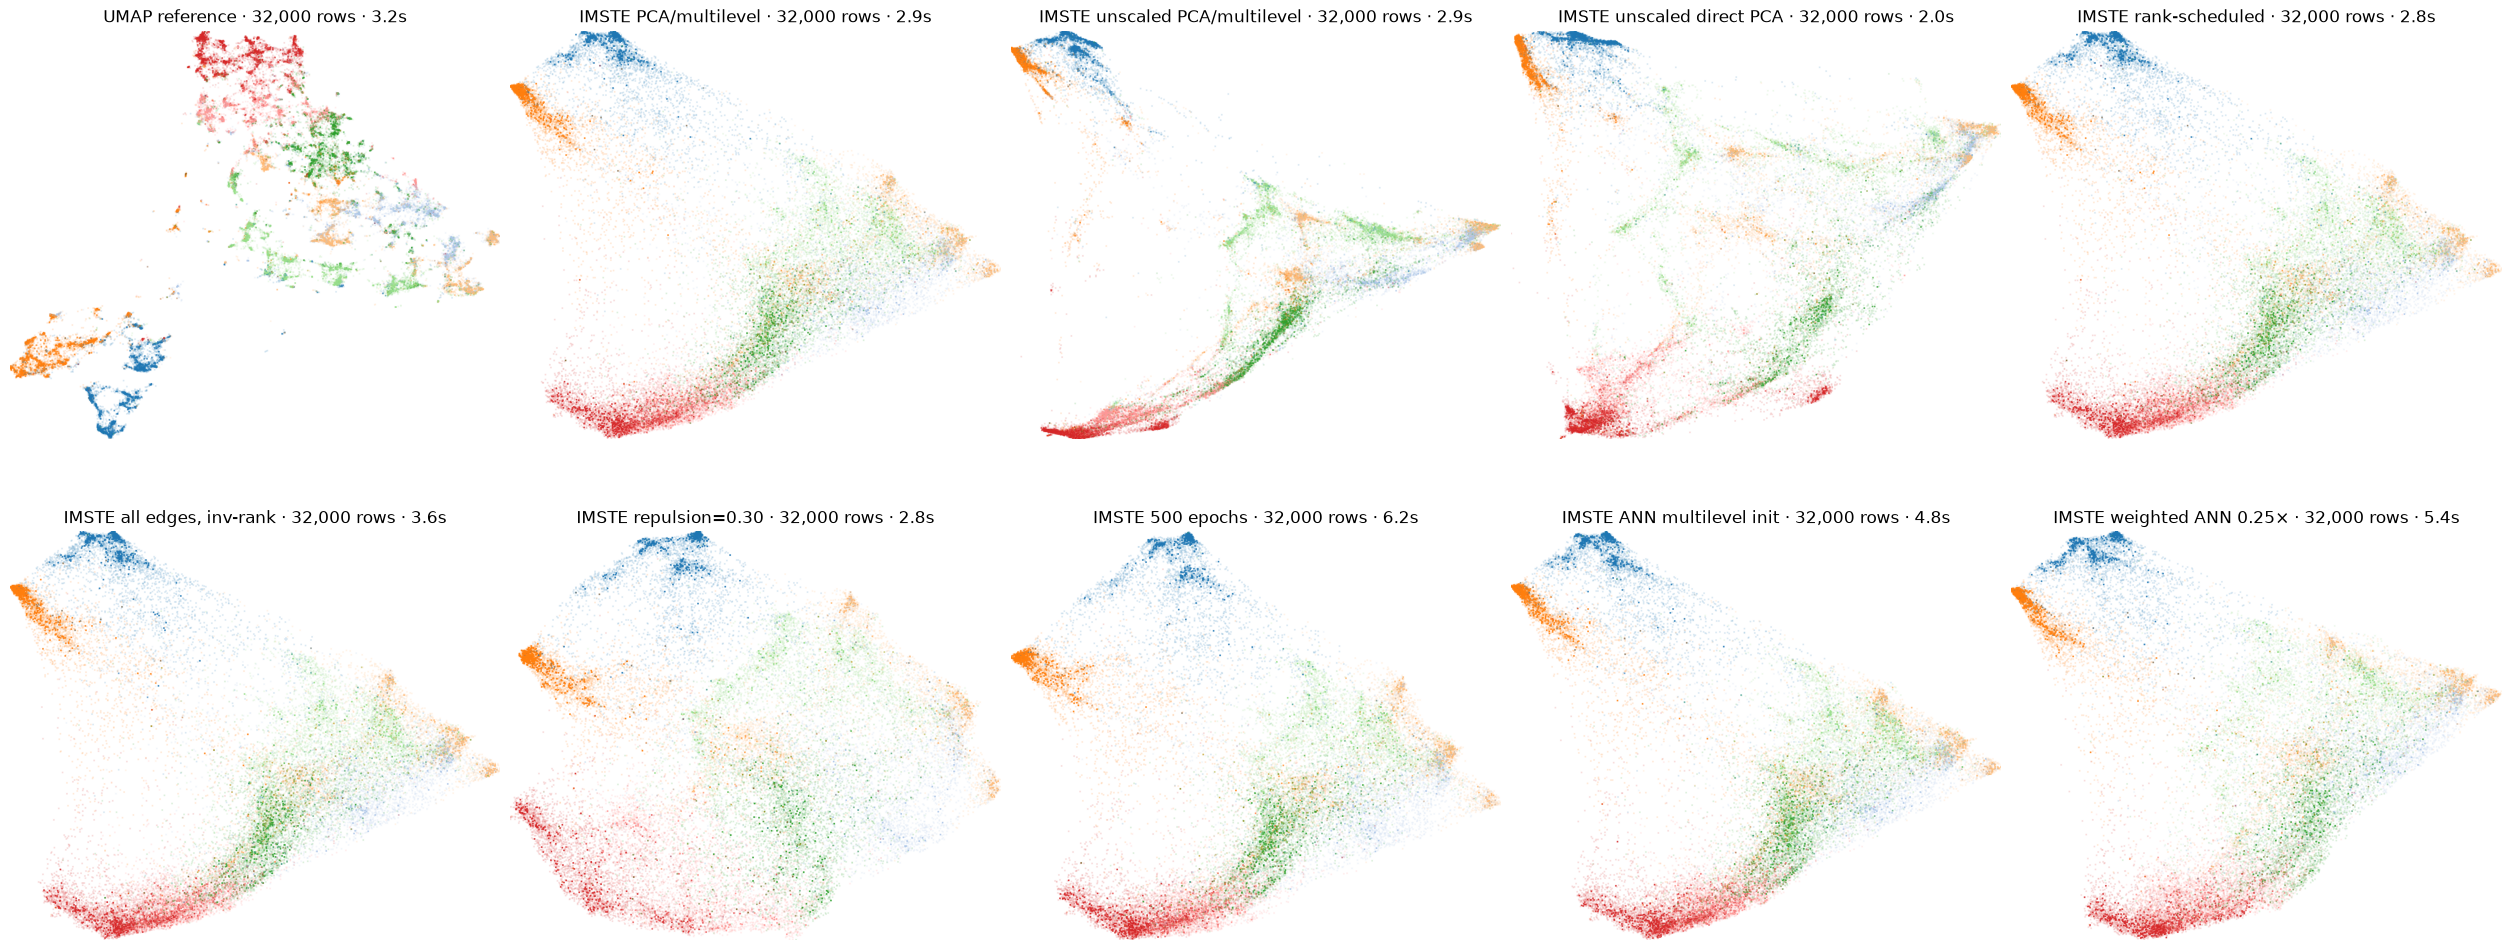

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
from imste.visualization import render_datashader_embedding

palette = plt.get_cmap("tab20")
class_order = list(labels_experiment.categories)
color_key = {label: to_hex(palette(i % palette.N)) for i, label in enumerate(class_order)}
label_values = pd.Series(np.asarray(labels_experiment)).astype(str)
layouts = [
    ("UMAP reference", Z_umap, umap_seconds),
    ("IMSTE PCA/multilevel", Z_imste_baseline, imste_baseline_seconds),
    ("IMSTE unscaled PCA/multilevel", Z_imste_pca_unscaled, imste_pca_unscaled_seconds),
    ("IMSTE unscaled direct PCA", Z_imste_pca_unscaled_direct, imste_pca_unscaled_direct_seconds),
    ("IMSTE rank-scheduled", Z_imste_rank_scheduled, imste_rank_scheduled_seconds),
    ("IMSTE all edges, inv-rank", Z_imste_all_weighted, imste_all_weighted_seconds),
    ("IMSTE repulsion=0.30", Z_imste_repulsion_03, imste_repulsion_03_seconds),
    ("IMSTE 500 epochs", Z_imste_500_epochs, imste_500_epochs_seconds),
    ("IMSTE ANN multilevel init", Z_imste_knn_multilevel, imste_knn_multilevel_seconds),
    ("IMSTE weighted ANN 0.25×", Z_weighted_knn_025, weighted_knn_025_seconds),
]
fig, axes = plt.subplots(2, 5, figsize=(25, 10), constrained_layout=True)
for ax, (name, coordinates, seconds) in zip(axes.ravel(), layouts):
    image = render_datashader_embedding(
        coordinates[:, :2], label_values, width=900, height=750,
        color_key=color_key, min_alpha=40, background="white", spread_px=1,
    )
    ax.imshow(image.to_pil())
    ax.set_title(f"{name} · {len(X_experiment):,} rows · {seconds:.1f}s")
    ax.set_axis_off()

display(fig)
plt.close(fig)


## Density-weighted attraction phase (prototype)

This first second-phase prototype starts from the unscaled PCA + multilevel IMSTE embedding and moves each point toward a density-weighted centroid of its RINND neighbors. Labels are used only for coloring and post-fit metrics, including an 8-domain silhouette score. They do not enter initialization or force calculations.

This early sweep used 16 candidate neighbors (it predates matching FAMST's exact 15-neighbor graph settings). It behaved like diffusion and did not tighten neighborhoods reliably. Treat it as a rejected local-smoothing prototype; the dense-core experiment below uses FAMST's RINND settings.

configuration,trustworthiness,input 15-NN overlap,domain purity,label silhouette,relative local radius
baseline,0.8743,0.0985,0.6791,0.0631,0.0089
mass exponent 2 · strength 0.03 · steps 1,0.8740,0.0953,0.6810,0.0628,0.0090
mass exponent 2 · strength 0.08 · steps 4,0.8660,0.0822,0.6675,0.0581,0.0095
mass exponent 2 · strength 0.08 · steps 8,0.8592,0.0778,0.6594,0.0521,0.0096
mass exponent 2 · strength 0.15 · steps 4,0.8599,0.0778,0.6618,0.0525,0.0095
mass exponent 2 · strength 0.15 · steps 8,0.8569,0.0796,0.6497,0.0412,0.0092
mass exponent 2 · strength 0.25 · steps 8,0.8606,0.0803,0.6363,0.0310,0.0088
mass exponent 4 · strength 0.25 · steps 8,0.8621,0.0879,0.6379,0.0208,0.0071


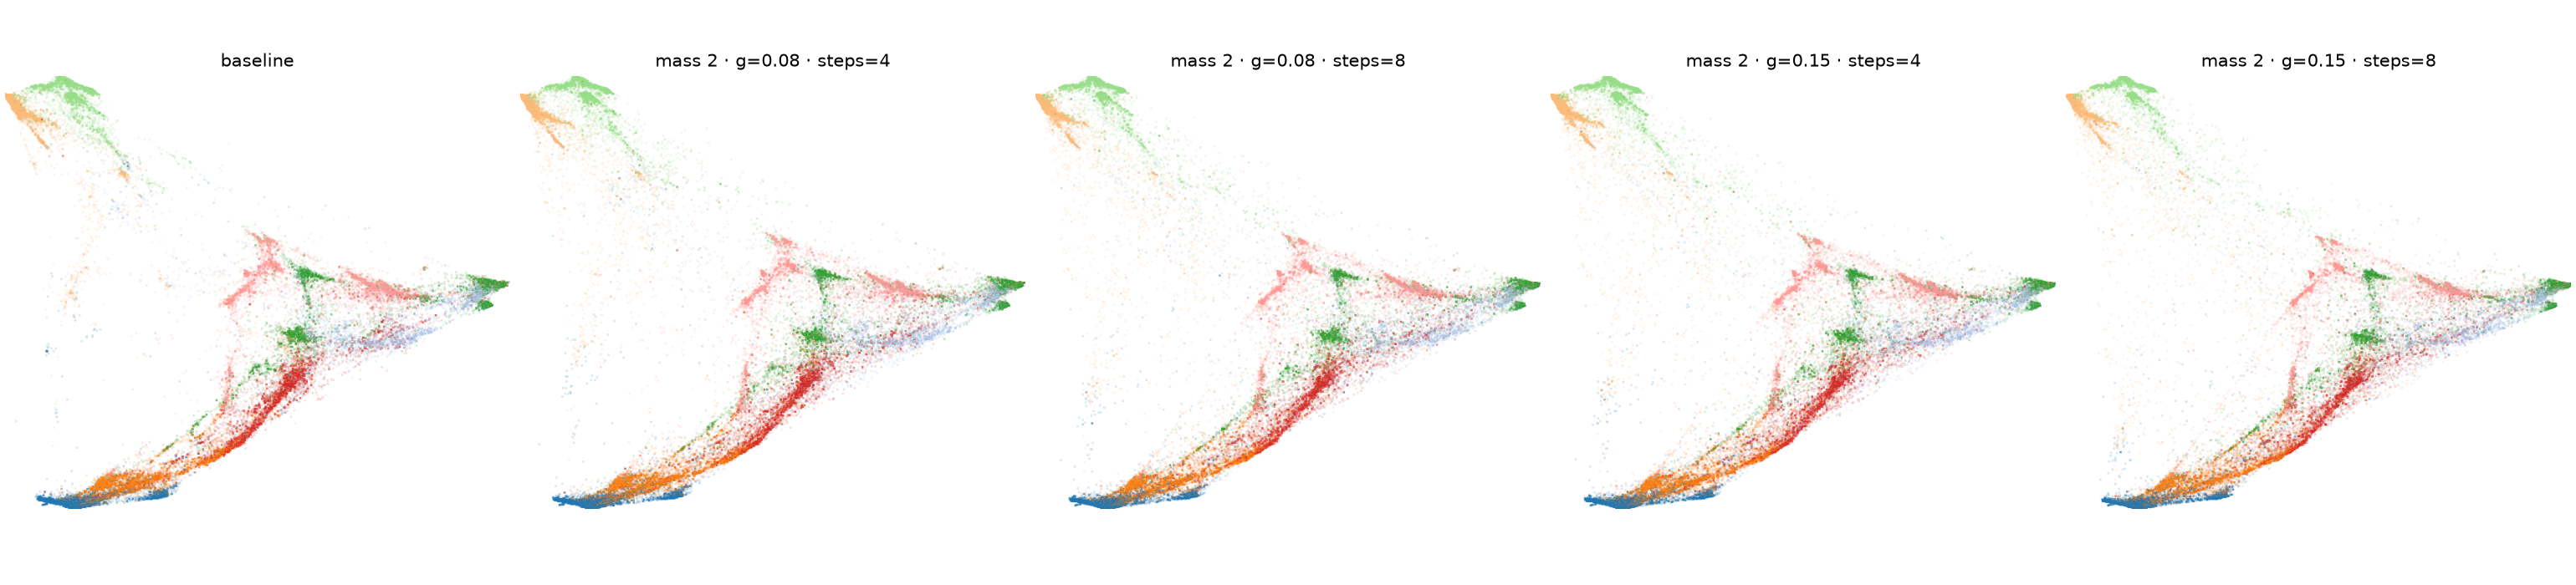

In [7]:
# Density-weighted second phase, using only X_experiment and the preferred IMSTE layout.
# UMAP coordinates are not involved in this experiment.
from rinnd import RINND
from sklearn.metrics import silhouette_score

GRAVITY_NEIGHBORS = 15
GRAVITY_MASS_EXPONENT = 2.0
_gravity_index = RINND(
    np.ascontiguousarray(X_experiment, dtype=np.float32),
    metric="euclidean", n_neighbors=GRAVITY_NEIGHBORS + 1,
    random_state=RANDOM_STATE, n_trees=8, n_iters=15,
    max_candidates=30, n_jobs=-1, verbose=False,
)
_gravity_indices, _gravity_distances = _gravity_index.neighbor_graph
_gravity_rows, _gravity_cols, _gravity_dists = [], [], []
for _i in range(len(X_experiment)):
    _keep = _gravity_indices[_i] != _i
    _js = np.asarray(_gravity_indices[_i][_keep][:GRAVITY_NEIGHBORS], dtype=np.int64)
    _ds = np.asarray(_gravity_distances[_i][_keep][:GRAVITY_NEIGHBORS], dtype=np.float32)
    _gravity_rows.extend([_i] * len(_js)); _gravity_cols.extend(_js.tolist()); _gravity_dists.extend(_ds.tolist())
_gravity_rows = np.asarray(_gravity_rows, dtype=np.int64)
_gravity_cols = np.asarray(_gravity_cols, dtype=np.int64)
_gravity_dists = np.asarray(_gravity_dists, dtype=np.float32)
_gravity_kth = np.asarray([
    np.max(_gravity_dists[_gravity_rows == _i]) for _i in range(len(X_experiment))
], dtype=np.float32)
_log_density = -np.log(np.maximum(_gravity_kth, 1e-12))
_log_density = (_log_density - np.median(_log_density)) / (
    np.median(np.abs(_log_density - np.median(_log_density))) + 1e-12
)
_gravity_mass = np.exp(np.clip(_log_density, -3, 3))
_gravity_base_weights = np.exp(
    -_gravity_dists / np.maximum(_gravity_kth[_gravity_rows], 1e-12)
)

def density_gravity_phase(coordinates, strength, steps, mass_exponent=GRAVITY_MASS_EXPONENT):
    edge_weights = _gravity_base_weights * _gravity_mass[_gravity_cols] ** mass_exponent
    row_weight = np.bincount(_gravity_rows, weights=edge_weights, minlength=len(coordinates))
    result = np.asarray(coordinates, dtype=np.float64).copy()
    for _ in range(steps):
        neighbor_mass = np.zeros_like(result)
        np.add.at(neighbor_mass, _gravity_rows, edge_weights[:, None] * result[_gravity_cols])
        neighbor_mass /= np.maximum(row_weight[:, None], 1e-15)
        result += strength * (neighbor_mass - result)
        result -= result.mean(axis=0)
    return result.astype(np.float32)

# Small sweep: keep the base embedding fixed and vary only force strength/steps.
gravity_configs = [
    (2.0, 0.03, 1), (2.0, 0.08, 4), (2.0, 0.08, 8),
    (2.0, 0.15, 4), (2.0, 0.15, 8), (2.0, 0.25, 8),
    (4.0, 0.25, 8),
]
gravity_results = [{"configuration": "baseline", **score_layout("baseline", Z_imste_pca_unscaled),
                   "label_silhouette": silhouette_score(
                       np.asarray(Z_imste_pca_unscaled), np.asarray(labels_experiment),
                       sample_size=min(5_000, len(X_experiment)), random_state=2027
                   )}]
gravity_embeddings = {"baseline": Z_imste_pca_unscaled}
for _mass, _strength, _steps in gravity_configs:
    _name = f"mass={_mass:g}, strength={_strength:g}, steps={_steps}"
    _z = density_gravity_phase(Z_imste_pca_unscaled, _strength, _steps, _mass)
    gravity_embeddings[_name] = _z
    gravity_results.append({"configuration": _name, **score_layout(_name, _z),
                           "label_silhouette": silhouette_score(
                               np.asarray(_z), np.asarray(labels_experiment),
                               sample_size=min(5_000, len(X_experiment)), random_state=2027
                           )})
gravity_table = pd.DataFrame(gravity_results)[[
    "configuration", "trustworthiness", "input_neighbor_overlap@15",
    "domain_purity@15", "label_silhouette",
    "median_15NN_radius / median_extent"
]]
display(gravity_table.round(4))

# Render the baseline and four intermediate force settings side by side.
from imste.visualization import render_datashader_embedding
from matplotlib.colors import to_hex
_gravity_palette = plt.get_cmap("tab20")
_gravity_labels = np.asarray(labels_experiment).astype(str)
_gravity_color_key = {label: to_hex(_gravity_palette(i % _gravity_palette.N))
                      for i, label in enumerate(pd.unique(_gravity_labels))}
_gravity_plot_names = ["baseline"] + [
    "mass=2, strength=0.08, steps=4", "mass=2, strength=0.08, steps=8",
    "mass=2, strength=0.15, steps=4", "mass=2, strength=0.15, steps=8",
]
fig, axes = plt.subplots(1, 5, figsize=(22, 5), constrained_layout=True)
for _ax, _name in zip(axes, _gravity_plot_names):
    _image = render_datashader_embedding(
        gravity_embeddings[_name], _gravity_labels, width=700, height=600,
        color_key=_gravity_color_key, min_alpha=40, background="white", spread_px=1,
    )
    _ax.imshow(_image.to_pil()); _ax.set_title(_name, fontsize=10); _ax.set_axis_off()
display(fig); plt.close(fig)


## Graph-region mass attraction: dense-core version

The local neighbor-centroid pass behaved like diffusion. This version partitions the feature-space RINND graph into Leiden communities, estimates density from each point's 15th-neighbor radius, and computes each community center from its densest **2%** of points. Every point in a community is pulled toward that dense core. The force coefficient is `strength × (region_mass / median_region_mass)`, capped at 0.9; region mass is the sum of density weights.

RINND uses the same graph-search settings as FAMST here: 15 neighbors, 8 trees, `max_candidates=22`, and `n_iters=max(5, round(log2(n)))`. Domain labels are used only for plot colors and evaluation. The 32k sweep keeps the unscaled PCA/multilevel IMSTE start fixed.

configuration,trustworthiness,input_neighbor_overlap@15,domain_purity@15,label_silhouette,median_15NN_radius / median_extent
baseline,0.8743,0.0985,0.6791,0.0631,0.0089
"strength=0.2, mass_power=1, core=98%",0.8722,0.1055,0.6810,0.0678,0.0074
"strength=0.4, mass_power=1, core=98%",0.8766,0.1144,0.6842,0.0660,0.0051
"strength=0.7, mass_power=1, core=98%",0.8916,0.1187,0.6970,0.0696,0.0019


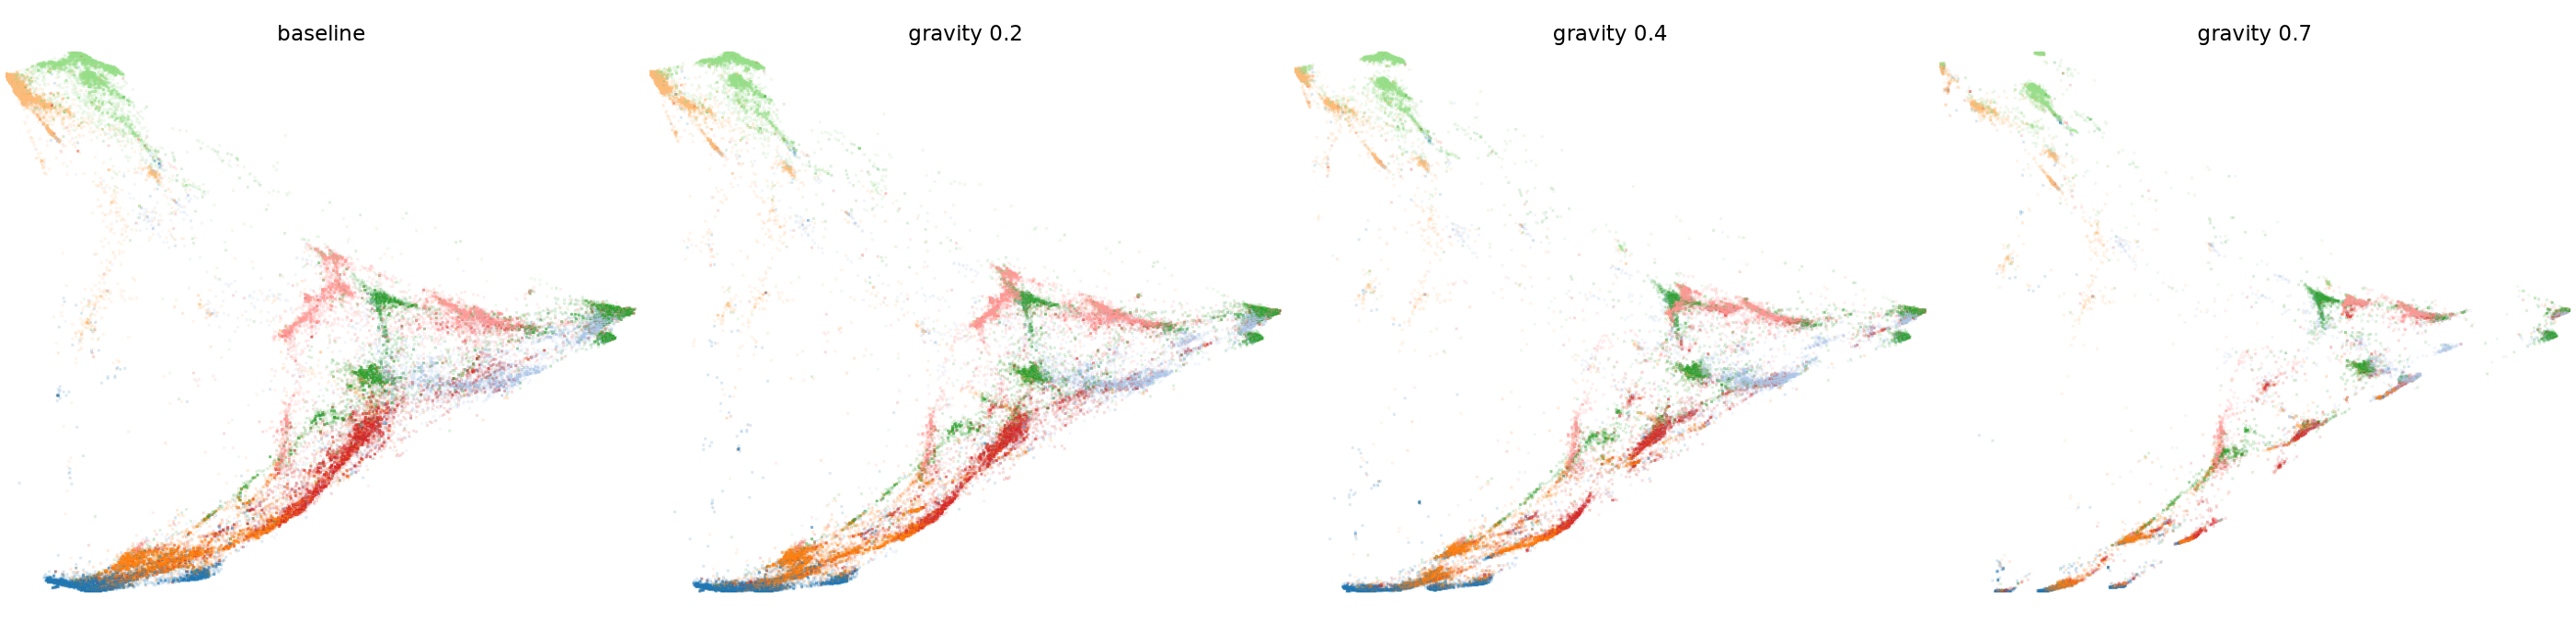

In [10]:
# Optional research dependencies for graph community detection.
try:
    import igraph as ig
    import leidenalg
except ImportError as exc:
    raise ImportError("Install experiment dependencies with `python -m pip install igraph leidenalg`.") from exc
from rinnd import RINND
from sklearn.metrics import silhouette_score

REGION_NEIGHBORS = 15
REGION_RESOLUTION = 1.2
REGION_CORE_QUANTILE = 0.98
_region_index = RINND(
    np.ascontiguousarray(X_experiment, dtype=np.float32), metric="euclidean",
    n_neighbors=REGION_NEIGHBORS, random_state=RANDOM_STATE,
    n_trees=8, n_iters=max(5, int(round(np.log2(len(X_experiment))))),
    max_candidates=max(20, min(60, int(1.5 * REGION_NEIGHBORS))), n_jobs=-1, verbose=False,
)
_region_indices, _region_distances = _region_index.neighbor_graph
_region_rows = np.repeat(np.arange(len(X_experiment)), _region_indices.shape[1])
_region_cols = np.asarray(_region_indices).reshape(-1).astype(np.int64)
_region_dists = np.asarray(_region_distances).reshape(-1).astype(np.float32)
_region_valid = (_region_cols != _region_rows) & np.isfinite(_region_dists)
_region_rows, _region_cols, _region_dists = (
    _region_rows[_region_valid], _region_cols[_region_valid], _region_dists[_region_valid]
)
_region_radius = np.max(
    np.where(_region_indices != np.arange(len(X_experiment))[:, None],
             _region_distances, -np.inf), axis=1
).astype(np.float32)
_node_mass_raw = (np.median(_region_radius) / np.maximum(_region_radius, 1e-12)) ** 2
_region_node_mass = np.clip(
    _node_mass_raw, np.percentile(_node_mass_raw, 1), np.percentile(_node_mass_raw, 99)
)
_region_edge_weights = np.exp(
    -_region_dists / np.maximum(_region_radius[_region_rows], 1e-12)
).astype(np.float32)
_region_graph = ig.Graph(
    n=len(X_experiment), edges=zip(_region_rows.tolist(), _region_cols.tolist()), directed=False
)
_region_graph.es["weight"] = _region_edge_weights.tolist()
_region_graph.simplify(multiple=True, loops=True, combine_edges={"weight": "sum"})
_region_partition = leidenalg.find_partition(
    _region_graph, leidenalg.RBConfigurationVertexPartition,
    weights="weight", resolution_parameter=REGION_RESOLUTION, seed=RANDOM_STATE,
)
_region_membership = np.asarray(_region_partition.membership, dtype=np.int64)
_region_count = int(_region_membership.max()) + 1
_region_masses = np.bincount(
    _region_membership, weights=_region_node_mass, minlength=_region_count
)
_region_thresholds = np.asarray([
    np.quantile(_region_node_mass[_region_membership == _j], REGION_CORE_QUANTILE)
    for _j in range(_region_count)
])
_region_core = _region_node_mass >= _region_thresholds[_region_membership]
_region_core_masses = np.bincount(
    _region_membership[_region_core], weights=_region_node_mass[_region_core], minlength=_region_count
)
_region_centers = np.zeros((_region_count, Z_imste_pca_unscaled.shape[1]), dtype=np.float64)
np.add.at(
    _region_centers, _region_membership[_region_core],
    np.asarray(Z_imste_pca_unscaled, dtype=np.float64)[_region_core]
    * _region_node_mass[_region_core, None],
)
_region_centers /= _region_core_masses[:, None]
_region_median_mass = np.median(_region_masses)

def apply_region_mass_attraction(coordinates, strength):
    region_strength = np.clip(
        strength * (_region_masses / _region_median_mass), 0.0, 0.9
    )
    result = np.asarray(coordinates, dtype=np.float64).copy()
    result += region_strength[_region_membership, None] * (
        _region_centers[_region_membership] - result
    )
    result -= result.mean(axis=0)
    return result.astype(np.float32)

region_strengths = [0.2, 0.4, 0.7]
region_results = [{
    "configuration": "baseline", **score_layout("baseline", Z_imste_pca_unscaled),
    "label_silhouette": silhouette_score(
        np.asarray(Z_imste_pca_unscaled), np.asarray(labels_experiment),
        sample_size=min(5_000, len(X_experiment)), random_state=2027
    ),
}]
region_embeddings = {"baseline": Z_imste_pca_unscaled}
for _strength in region_strengths:
    _name = f"strength={_strength:g}, mass_power=1, core=98%"
    _z = apply_region_mass_attraction(Z_imste_pca_unscaled, _strength)
    region_embeddings[_name] = _z
    region_results.append({
        "configuration": _name, **score_layout(_name, _z),
        "label_silhouette": silhouette_score(
            np.asarray(_z), np.asarray(labels_experiment),
            sample_size=min(5_000, len(X_experiment)), random_state=2027
        ),
    })
region_table = pd.DataFrame(region_results)[[
    "configuration", "trustworthiness", "input_neighbor_overlap@15",
    "domain_purity@15", "label_silhouette",
    "median_15NN_radius / median_extent",
]]
display(region_table.round(4))

_region_labels = np.asarray(labels_experiment).astype(str)
_region_palette = plt.get_cmap("tab20")
_region_color_key = {label: to_hex(_region_palette(i % _region_palette.N))
                      for i, label in enumerate(pd.unique(_region_labels))}
_region_names = ["baseline"] + [
    f"strength={s:g}, mass_power=1, core=98%" for s in region_strengths
]
fig, axes = plt.subplots(1, 4, figsize=(21, 5), constrained_layout=True)
for _ax, _name in zip(axes, _region_names):
    _image = render_datashader_embedding(
        region_embeddings[_name], _region_labels, width=700, height=650,
        color_key=_region_color_key, min_alpha=40, background="white", spread_px=1,
    )
    _ax.imshow(_image.to_pil()); _ax.set_title(_name, fontsize=9); _ax.set_axis_off()
display(fig); plt.close(fig)


## Full-size confirmation: 640,000 papers

All rows use the same deterministic random 640k sample (`data_id=3605bdd0d9fb967ec06f`, seed 42). Trustworthiness and input-neighbor overlap use exact 15-neighbor ranks for 512 fixed anchors; purity uses those anchors; silhouette is sampled over 5,000 rows with seed 2027. Labels are used only for post-fit scores and plot colors.

The current compactness candidate is **3 MSTs plus density-core gravity on a 21-region Leiden partition (resolution 0.8, core quantile 0.95, strength 0.4)**. Compared with the unscaled-PCA 5-MST baseline, trustworthiness changes from 0.860 to 0.867, input 15-NN overlap from 0.0133 to 0.0273, domain purity from 0.795 to 0.806, macro purity from 0.400 to 0.439, and silhouette from 0.054 to 0.145. The normalized 15-NN radius falls from 0.00182 to 0.00075 (59% smaller). The 3-MST fit takes about 50s; RINND graph construction and Leiden partition take about 108s, for about 157s end-to-end, compared with 309s for the UMAP reference.

Resolution 3 with the same strength has higher trustworthiness (0.917) but a larger normalized local radius (0.00104). The fixed rendering shows resolution 0.8 gives more compact, better separated regions while retaining a U-shaped global fan. This is the best tested compactness tradeoff, not a complete solution to the global shape. One MST scores higher but produces sparse, strand-like branches; adding local attraction edges did not improve the overall tradeoff. UMAP remains a reference only; no UMAP coordinates initialize any IMSTE experiment.


layout,total seconds,trustworthiness,input 15-NN overlap,domain purity,macro domain purity,label silhouette (5k),relative local radius
UMAP reference (no IMSTE initialization),308.84,0.9770,0.0772,0.8430,0.5633,0.0747,0.0035
IMSTE 5 MST baseline,89.55,0.8602,0.0133,0.7951,0.3997,0.0544,0.0018
IMSTE 1 MST (strand-like; reject),29.87,0.9630,0.1474,0.8177,0.5401,0.1831,0.0001
IMSTE 2 MST,38.92,0.8559,0.0199,0.7790,0.3774,0.0820,0.0014
IMSTE 3 MST (leading base),49.64,0.8738,0.0195,0.7999,0.3950,0.1456,0.0017
"3 MST, repulsion 0.025",94.78,0.8706,0.0189,0.8018,0.3892,0.1451,0.0016
"3 MST, repulsion 0.075",67.28,0.8753,0.0204,0.8010,0.3932,0.1461,0.0019
5 MST + sparse local edges (weight 0.2),114.30,0.8608,0.0168,0.7906,0.3895,0.0549,0.0019
"3 MST + 90 regions, gravity 0.2",156.80,0.8874,0.0245,0.8070,0.3960,0.1391,0.0014
"3 MST + 90 regions, gravity 0.3",156.80,0.8942,0.0281,0.8076,0.4011,0.1350,0.0013


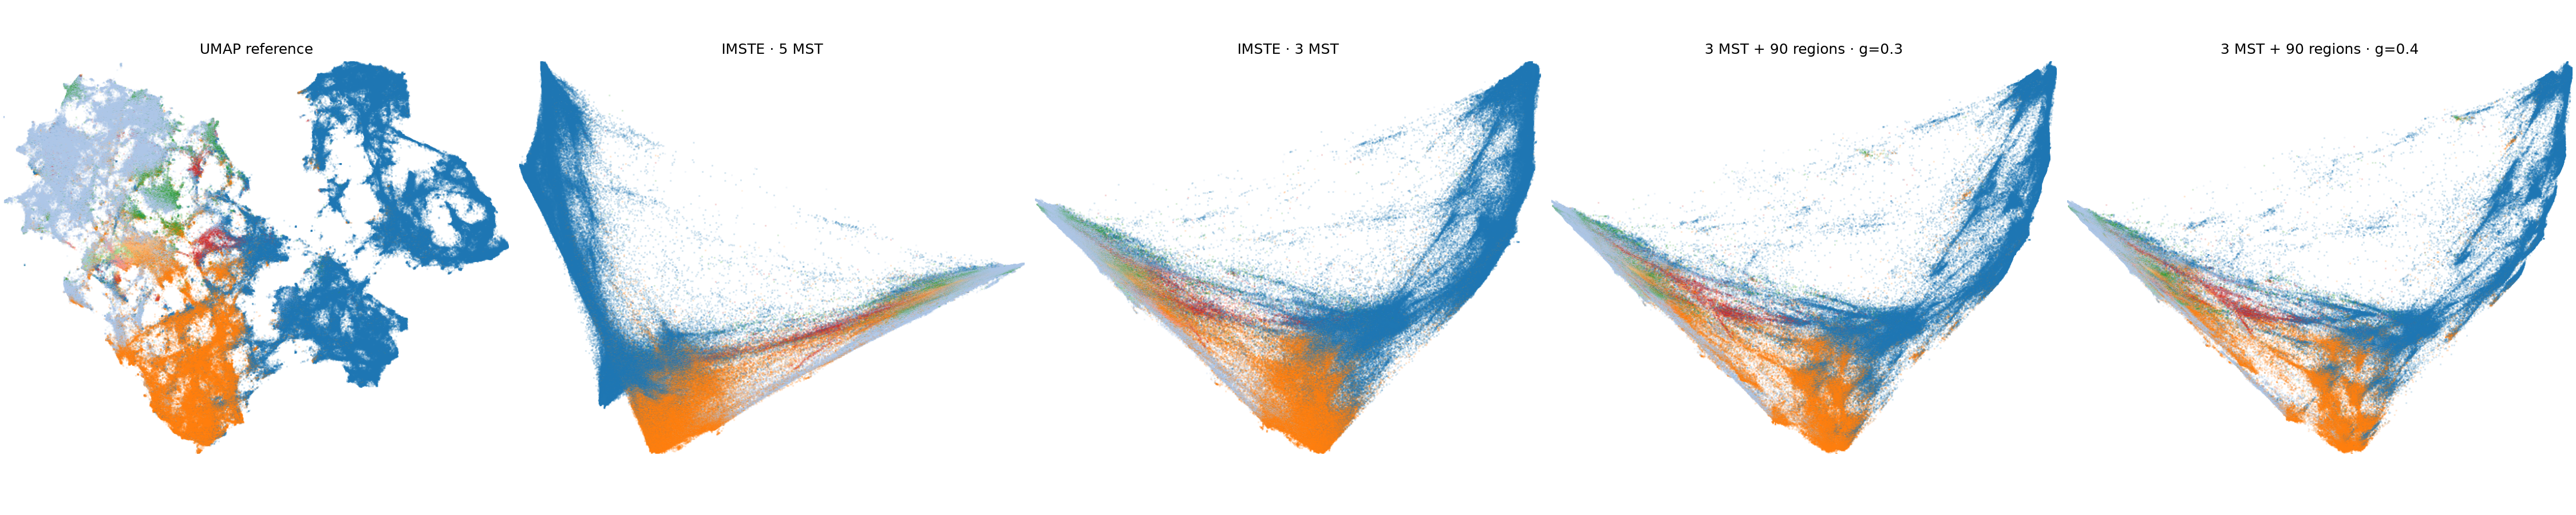

In [11]:
# Captured fixed-seed 640k comparisons. Labels appear only in scoring and color.
full_size_results = pd.DataFrame([
    {'layout': 'UMAP reference (no IMSTE initialization)', 'total seconds': 308.84, 'trustworthiness': 0.977022, 'input 15-NN overlap': 0.077214, 'domain purity': 0.842969, 'macro domain purity': 0.563316, 'label silhouette (5k)': 0.07472, 'relative local radius': 0.003539},
    {'layout': 'IMSTE 5 MST baseline', 'total seconds': 89.55, 'trustworthiness': 0.860163, 'input 15-NN overlap': 0.013281, 'domain purity': 0.795052, 'macro domain purity': 0.399725, 'label silhouette (5k)': 0.054447, 'relative local radius': 0.001816},
    {'layout': 'IMSTE 1 MST (strand-like; reject)', 'total seconds': 29.87, 'trustworthiness': 0.962981, 'input 15-NN overlap': 0.147396, 'domain purity': 0.817708, 'macro domain purity': 0.540108, 'label silhouette (5k)': 0.183078, 'relative local radius': 0.000102},
    {'layout': 'IMSTE 2 MST', 'total seconds': 38.92, 'trustworthiness': 0.855865, 'input 15-NN overlap': 0.019922, 'domain purity': 0.779036, 'macro domain purity': 0.3774, 'label silhouette (5k)': 0.081952, 'relative local radius': 0.001427},
    {'layout': 'IMSTE 3 MST (leading base)', 'total seconds': 49.64, 'trustworthiness': 0.87375, 'input 15-NN overlap': 0.019531, 'domain purity': 0.79987, 'macro domain purity': 0.394995, 'label silhouette (5k)': 0.145551, 'relative local radius': 0.001704},
    {'layout': '3 MST, repulsion 0.025', 'total seconds': 94.78, 'trustworthiness': 0.870589, 'input 15-NN overlap': 0.01888, 'domain purity': 0.801823, 'macro domain purity': 0.389218, 'label silhouette (5k)': 0.145091, 'relative local radius': 0.001561},
    {'layout': '3 MST, repulsion 0.075', 'total seconds': 67.28, 'trustworthiness': 0.87529, 'input 15-NN overlap': 0.020443, 'domain purity': 0.801042, 'macro domain purity': 0.39323, 'label silhouette (5k)': 0.146059, 'relative local radius': 0.001879},
    {'layout': '5 MST + sparse local edges (weight 0.2)', 'total seconds': 114.3, 'trustworthiness': 0.860793, 'input 15-NN overlap': 0.016797, 'domain purity': 0.790625, 'macro domain purity': 0.389516, 'label silhouette (5k)': 0.054864, 'relative local radius': 0.001873},
    {'layout': '3 MST + 90 regions, gravity 0.2', 'total seconds': 156.8, 'trustworthiness': 0.887441, 'input 15-NN overlap': 0.024479, 'domain purity': 0.807031, 'macro domain purity': 0.395973, 'label silhouette (5k)': 0.139088, 'relative local radius': 0.001432},
    {'layout': '3 MST + 90 regions, gravity 0.3', 'total seconds': 156.8, 'trustworthiness': 0.894215, 'input 15-NN overlap': 0.028125, 'domain purity': 0.807552, 'macro domain purity': 0.401121, 'label silhouette (5k)': 0.134999, 'relative local radius': 0.00129},
    {'layout': '3 MST + 90 regions, gravity 0.4 (leading candidate)', 'total seconds': 156.8, 'trustworthiness': 0.916896, 'input 15-NN overlap': 0.033724, 'domain purity': 0.81849, 'macro domain purity': 0.438073, 'label silhouette (5k)': 0.13106, 'relative local radius': 0.001041},
    {'layout': '3 MST + 90 regions, gravity 0.7', 'total seconds': 156.8, 'trustworthiness': 0.935638, 'input 15-NN overlap': 0.040755, 'domain purity': 0.830208, 'macro domain purity': 0.452147, 'label silhouette (5k)': 0.117609, 'relative local radius': 0.000505},
    {'layout': '3 MST + 21 regions, gravity 0.4 (compactness candidate)', 'total seconds': 157.37, 'trustworthiness': 0.867469, 'input 15-NN overlap': 0.027344, 'domain purity': 0.806250, 'macro domain purity': 0.438620, 'label silhouette (5k)': 0.145280, 'relative local radius': 0.000750},
])
display(full_size_results.round(4))

# Plot uses the cached 640k coordinates from the experiments above.
from IPython.display import Image as _NotebookImage, display
_full_size_plot = EXPERIMENT_CACHE_DIR / "confirm640_resolution08_gravity_comparison.png"
if _full_size_plot.is_file():
    display(_NotebookImage(filename=str(_full_size_plot)))
else:
    print(f"Full-size plot not found: {_full_size_plot}")
